# Sentiment Analysis of Amazon Product Reviews — and the Effect of Review Length

**Problem.** Classify product reviews as positive or negative and examine how review length affects
classification accuracy.

**Data.** Real records from Hugging Face `fancyzhx/amazon_polarity` (Zhang et al., 2015):
`train-00000-of-00004.parquet` (900k reviews) and `test-00000-of-00001.parquet` (400k reviews).
No synthetic data is used anywhere.

**Pipeline.** data prep → length groups → TF-IDF+LR / Simple RNN / BiLSTM / Chunked BiLSTM →
per-length evaluation → calibration & human-review flagging → error analysis.

All heavy lifting lives in `src/`; this notebook calls the same functions as `main.py` and shows the outputs.
Neural training is slow-ish, so by default the notebook **loads the checkpoints trained by `python main.py`**.
Set `RETRAIN = True` to retrain everything inside the notebook.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import pandas as pd, numpy as np, torch
from IPython.display import Image, display
from src import config as C
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
C.set_seed()
RETRAIN = False
print("device:", C.get_device(), "| torch", torch.__version__)

device: mps | torch 2.15.0


## 1. Data preparation
`src/data_prep.py` — combine title+content, drop empty/duplicate rows, balanced sampling (80k train-file → 85/15 train/val, 20k test-file), cleaning (lower-case, strip HTML/URLs, keep negations and !/?), tokenisation, token counts. The script is fully seeded, so re-running it reproduces identical CSVs.

In [2]:
from src import data_prep
th = data_prep.main()

Loading raw parquet files ...


  train-00000-of-00004.parquet: 900,000 rows | removed 0 empty, 13 duplicates


  test-00000-of-00001.parquet: 400,000 rows | removed 0 empty, 1 duplicates


  removed 3 test rows that also occur in the train file
Sampling + cleaning ...


Length thresholds (train): {'q25': 45.0, 'median': 74.0, 'q75': 113.0, 'max_len_p95': 167}


  saved train.csv  (68,000 rows)
  saved val.csv  (12,000 rows)


  saved test.csv  (20,000 rows)

Dataset statistics:
 split                   train    val   test
n                       68000  12000  20000
n_neg                   34000   6000  10000
n_pos                   34000   6000  10000
pct_pos                  50.0   50.0   50.0
mean_tokens             82.54  81.94  80.62
median_tokens            74.0   73.0   71.0
std_tokens               44.5  44.15  44.07
min_tokens                  4     15     11
p5                       25.0   26.0   25.0
p25                      45.0   45.0   44.0
p75                     113.0  113.0  112.0
p90                     150.0  148.0  148.0
p95                     167.0  165.0  165.0
p99                     187.0  187.0  186.0
max_tokens                253    218    225
n_truncated_at_max_len   3399    519    879
pct_truncated             5.0   4.32    4.4

Class balance / truncation inside each length group:
 split        grouping group     n  pct_of_split  pct_pos  mean_tokens  min_tokens  max_tokens  n_tr

In [3]:
train = pd.read_csv(C.TRAIN_CSV); val = pd.read_csv(C.VAL_CSV); test = pd.read_csv(C.TEST_CSV)
print({k: len(v) for k, v in dict(train=train, val=val, test=test).items()})
train[["label", "text", "clean_text", "tokens", "token_count"]].head(3)

{'train': 68000, 'val': 12000, 'test': 20000}


,label,text,clean_text,tokens,token_count
0,1,"great classisist rock. If you enjoy a straight rock sound and want to go beyond ""Layla"" and ""Stairway to heaven,"" if...","great classisist rock. if you enjoy a straight rock sound and want to go beyond ""layla"" and ""stairway to heaven,"" if...",great classisist rock if you enjoy a straight rock sound and want to go beyond layla and stairway to heaven if your ...,167
1,1,"OK for talk radio, not recommeded for music. The sound quality is not great. I use it for listening to NPR only. I w...","ok for talk radio, not recommeded for music. the sound quality is not great. i use it for listening to npr only. i w...",ok for talk radio not recommeded for music the sound quality is not great i use it for listening to npr only i wo n'...,31
2,1,"For the already initiated, not the new Beach Boys fan. Tracks that separate out the vocals and non-singled album tra...","for the already initiated, not the new beach boys fan. tracks that separate out the vocals and non-singled album tra...",for the already initiated not the new beach boys fan tracks that separate out the vocals and non singled album track...,156


In [4]:
pd.read_csv(C.TABLE_DIR / "dataset_stats.csv").set_index("split").T

split,train,val,test
n,68000.00,12000.00,20000.00
n_neg,34000.00,6000.00,10000.00
n_pos,34000.00,6000.00,10000.00
pct_pos,50.00,50.00,50.00
mean_tokens,82.54,81.94,80.62
median_tokens,74.00,73.00,71.00
std_tokens,44.50,44.15,44.07
min_tokens,4.00,15.00,11.00
p5,25.00,26.00,25.00
p25,45.00,45.00,44.00


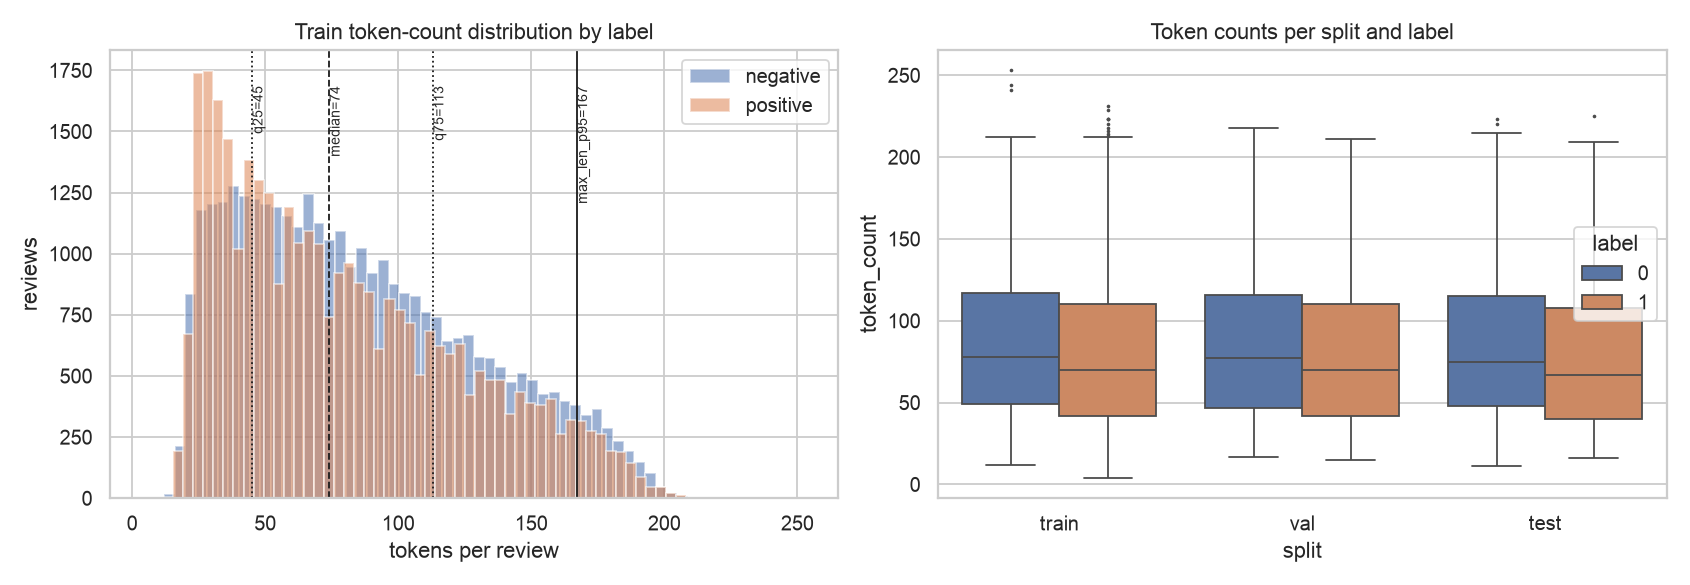

,label,count,mean,std,min,25%,50%,75%,max,pointbiserial_r,pointbiserial_p,mannwhitney_p
0,0,34000.0,85.7466,44.2494,12.0,49.0,78.0,117.0,253.0,-0.0722,0.0,0.0
1,1,34000.0,79.3254,44.5090,4.0,42.0,70.0,110.0,231.0,-0.0722,0.0,0.0


In [5]:
display(Image(C.FIG_DIR / "length_histogram.png"))
pd.read_csv(C.TABLE_DIR / "label_vs_length.csv").round(4)

## 2. Length groups
Thresholds are computed on **train only** and applied to val/test: two-way split (short ≤ median < long) and quartile bins Q1–Q4. `max_len` for the neural models = 95th percentile of train token counts.

In [6]:
print(json.dumps(th, indent=2))
g = pd.read_csv(C.TABLE_DIR / "length_group_stats.csv")
g[g.split == "test"]

{
  "q25": 45.0,
  "median": 74.0,
  "q75": 113.0,
  "max_len_p95": 167
}


,split,grouping,group,n,pct_of_split,pct_pos,mean_tokens,min_tokens,max_tokens,n_truncated,pct_truncated
12,test,length_2way,long,9491,47.45,46.75,119.2,75,225,879,9.26
13,test,length_2way,short,10509,52.55,52.94,45.7,11,74,0,0.00
14,test,length_quartile,Q1,5322,26.61,57.65,32.6,11,45,0,0.00
15,test,length_quartile,Q2,5187,25.93,48.10,59.3,46,74,0,0.00
16,test,length_quartile,Q3,4679,23.39,46.53,92.7,75,113,0,0.00
17,test,length_quartile,Q4,4812,24.06,46.97,145.1,114,225,879,18.27


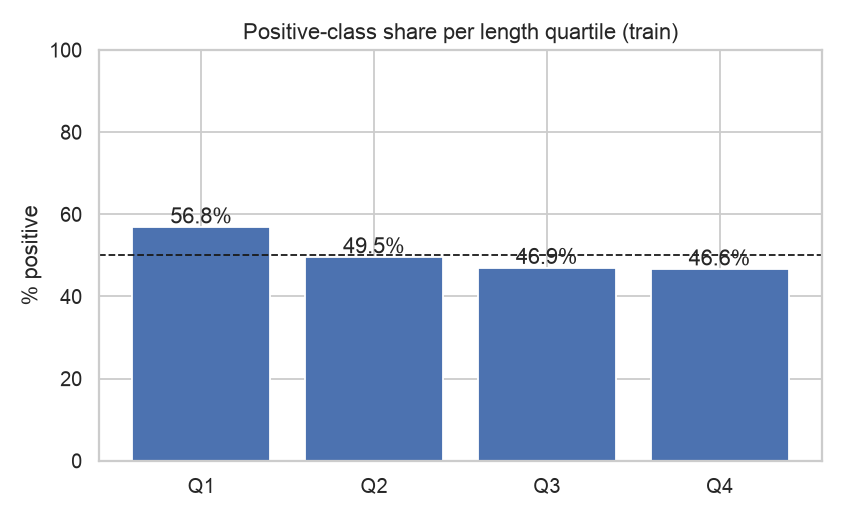

In [7]:
display(Image(C.FIG_DIR / "class_balance_by_quartile.png"))

## 3. Models
### 3a. TF-IDF (uni+bigrams) + Logistic Regression
Fit on train only; C picked on the validation set by log-loss.

In [8]:
if RETRAIN or not (C.MODELS_DIR / "tfidf_lr.joblib").exists():
    from src import train_baseline; train_baseline.main()
pd.read_csv(C.TABLE_DIR / "tfidf_lr_C_search.csv")

,C,val_accuracy,val_logloss
0,0.5,0.904250,0.301858
1,1.0,0.911083,0.265755
2,2.0,0.915417,0.239042
3,4.0,0.918417,0.221099
4,8.0,0.919833,0.211205
5,16.0,0.918333,0.208422
6,32.0,0.917250,0.211501
7,64.0,0.917000,0.219212


### 3b/3c. Simple RNN and BiLSTM
Vocabulary = top 20k train tokens + `<PAD>`, `<OOV>`; head truncation at `max_len`; dropout, AdamW, LR halving on plateau, early stopping on validation loss (patience 3). Best checkpoints are in `models/`.

Simple RNN: best epoch 7, val_loss 0.4132, val_acc 0.8357, params 2,593,409, train time 3.5 min


,epoch,train_loss,train_acc,val_loss,val_acc,lr,seconds,total_train_minutes
0,1,0.6667,0.5965,0.6512,0.6521,0.0010,23.4007,3.4905
1,2,0.6112,0.6779,0.5449,0.7430,0.0010,20.4023,3.4905
2,3,0.5534,0.7291,0.5047,0.7857,0.0010,20.2977,3.4905
3,4,0.5377,0.7465,0.4640,0.8012,0.0010,20.5652,3.4905
4,5,0.4985,0.7720,0.5160,0.7750,0.0005,21.4682,3.4905
5,6,0.4601,0.7989,0.4650,0.7978,0.0002,21.4400,3.4905
6,7,0.4385,0.8109,0.4132,0.8358,0.0002,20.4377,3.4905
7,8,0.4271,0.8155,0.4340,0.8283,0.0001,20.4173,3.4905
8,9,0.4070,0.8260,0.4179,0.8378,0.0001,20.6224,3.4905
9,10,0.3999,0.8301,0.4208,0.8322,0.0000,20.3134,3.4905


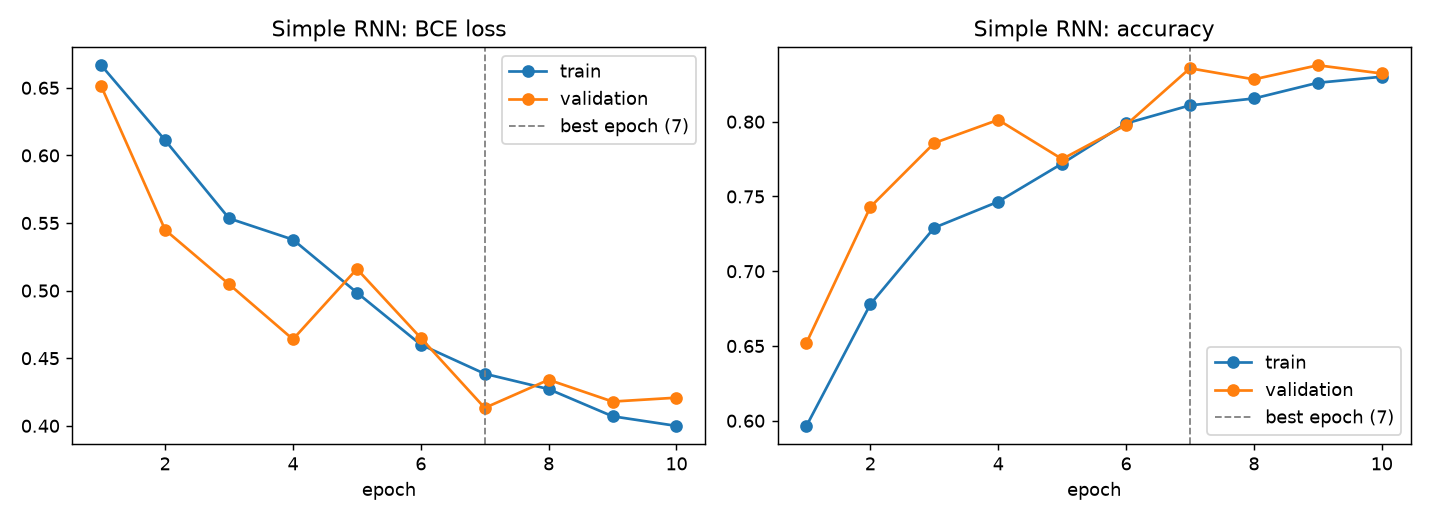

BiLSTM: best epoch 6, val_loss 0.3015, val_acc 0.9023, params 2,824,961, train time 13.6 min


,epoch,train_loss,train_acc,val_loss,val_acc,lr,seconds,total_train_minutes
0,1,0.4747,0.7621,0.4807,0.8348,0.0010,101.1151,13.5685
1,2,0.3233,0.8608,0.3427,0.8858,0.0010,91.0260,13.5685
2,3,0.2675,0.8884,0.3833,0.8640,0.0005,88.9228,13.5685
3,4,0.2337,0.9041,0.3414,0.8955,0.0005,88.5618,13.5685
4,5,0.2199,0.9111,0.3060,0.9023,0.0005,88.9915,13.5685
5,6,0.2106,0.9151,0.3015,0.9023,0.0005,89.0502,13.5685
6,7,0.2008,0.9198,0.3107,0.9092,0.0002,88.8170,13.5685
7,8,0.1898,0.9250,0.3185,0.9098,0.0001,88.5437,13.5685
8,9,0.1822,0.9283,0.3243,0.9076,0.0001,89.0000,13.5685


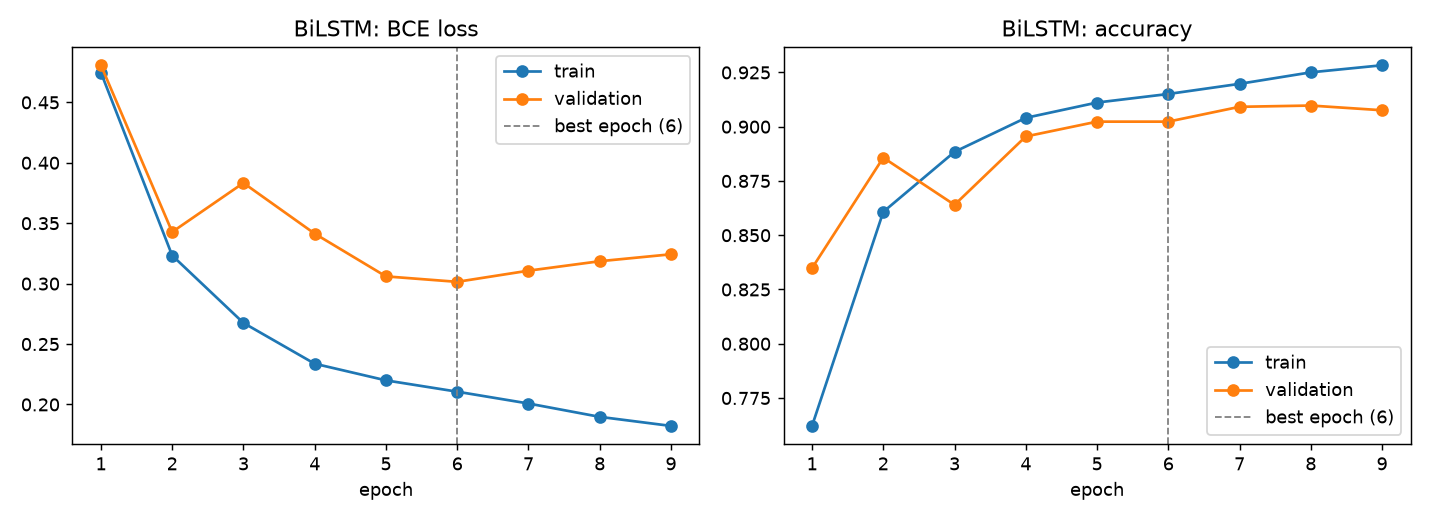

In [9]:
from src import train_nn
for kind in ("rnn", "lstm"):
    if RETRAIN or not (C.MODELS_DIR / f"{kind}_best.pt").exists():
        train_nn.train(kind)
for kind in ("rnn", "lstm"):
    h = pd.read_csv(C.TABLE_DIR / f"training_history_{kind}.csv")
    ck = torch.load(C.MODELS_DIR / f"{kind}_best.pt", map_location="cpu", weights_only=False)
    print(f"{C.MODEL_NAMES[kind]}: best epoch {ck['epoch']}, val_loss {ck['val_loss']:.4f}, "
          f"val_acc {ck['val_acc']:.4f}, params {ck['n_params']:,}, "
          f"train time {h.total_train_minutes.iloc[0]:.1f} min")
    display(h.round(4))
    display(Image(C.FIG_DIR / f"training_curves_{kind}.png"))

### 3d. Chunked BiLSTM (feature A)
Every review is split into sentence-based chunks of ≤ 50 tokens; the trained BiLSTM scores each chunk and the scores are combined by confidence-weighted averaging. A *hybrid* variant (chunk only reviews longer than `max_len`) is reported as an extra comparison.

In [10]:
from src import chunked
chunked.main()

[chunked] val: 12,000 reviews, mean chunks/review = 2.39, max = 7


[chunked] test: 20,000 reviews, mean chunks/review = 2.35, max = 7


## 4. Evaluation on the held-out test set

In [11]:
from src import evaluate
evaluate.main()


Overall test metrics:
        model      model_name     n  accuracy  precision  recall     f1
    tfidf_lr TF-IDF + LogReg 20000    0.9176     0.9206  0.9140 0.9173
         rnn      Simple RNN 20000    0.8340     0.8462  0.8163 0.8310
        lstm          BiLSTM 20000    0.9015     0.8639  0.9532 0.9063
chunked_lstm  Chunked BiLSTM 20000    0.8964     0.8556  0.9537 0.9020

By length group:
        model      model_name grouping group  pct_pos     n  accuracy  precision  recall     f1
    tfidf_lr TF-IDF + LogReg  two_way short  52.9356 10509    0.9229     0.9270  0.9274 0.9272
    tfidf_lr TF-IDF + LogReg  two_way  long  46.7496  9491    0.9117     0.9124  0.8972 0.9048
    tfidf_lr TF-IDF + LogReg quartile    Q1  57.6475  5322    0.9262     0.9367  0.9351 0.9359
    tfidf_lr TF-IDF + LogReg quartile    Q2  48.1010  5187    0.9196     0.9153  0.9178 0.9165
    tfidf_lr TF-IDF + LogReg quartile    Q3  46.5270  4679    0.9143     0.9150  0.8994 0.9071
    tfidf_lr TF-IDF + LogReg qua

In [12]:
pd.read_csv(C.TABLE_DIR / "metrics_overall.csv").round(4)

,model,model_name,n,accuracy,precision,recall,f1
0,tfidf_lr,TF-IDF + LogReg,20000,0.9176,0.9206,0.9140,0.9173
1,rnn,Simple RNN,20000,0.8340,0.8462,0.8163,0.8310
2,lstm,BiLSTM,20000,0.9015,0.8639,0.9532,0.9063
3,chunked_lstm,Chunked BiLSTM,20000,0.8964,0.8556,0.9537,0.9020


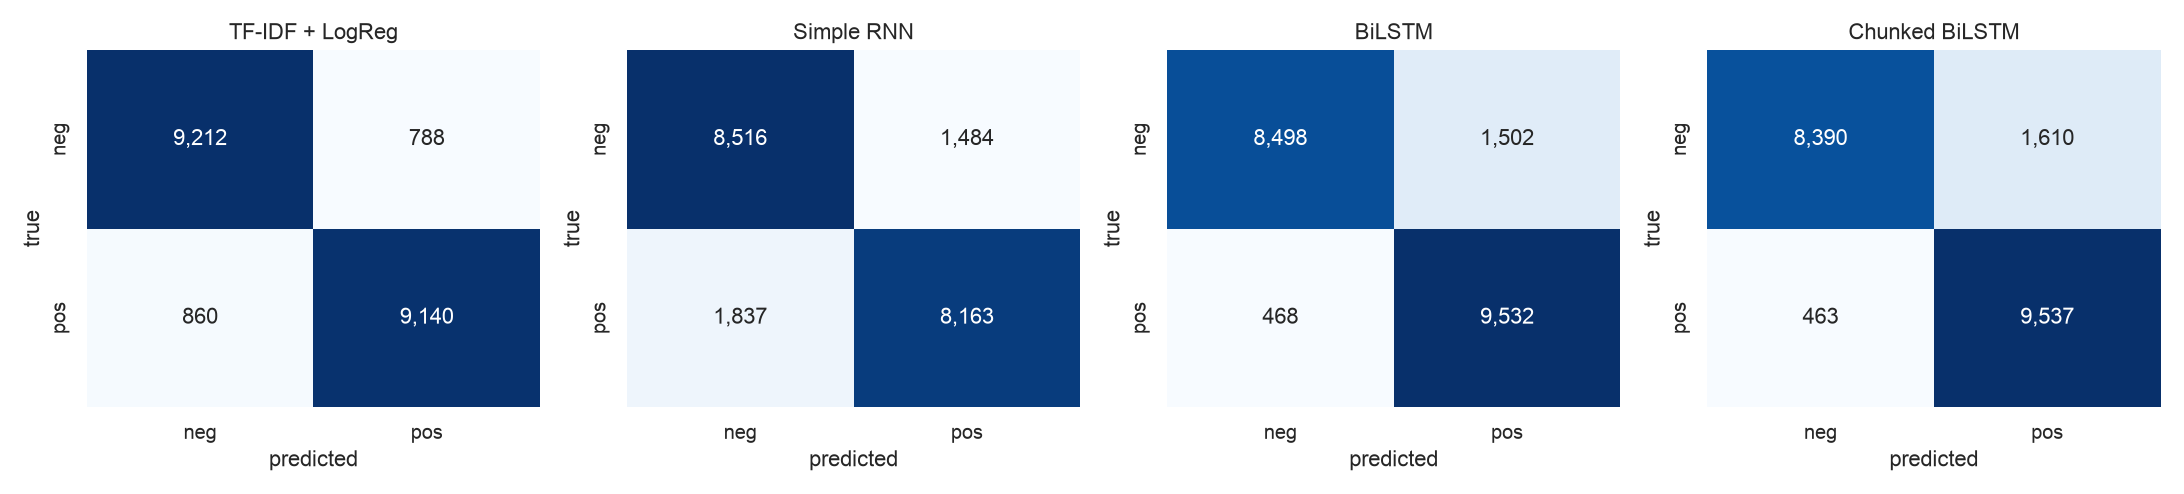

In [13]:
display(Image(C.FIG_DIR / "confusion_matrices.png"))

In [14]:
grp = pd.read_csv(C.TABLE_DIR / "metrics_by_length_group.csv")
grp.pivot_table(index=["grouping", "group"], columns="model_name", values="f1").round(4)

model_name      BiLSTM  Chunked BiLSTM  Simple RNN  TF-IDF + LogReg
grouping group                                                     
quartile Q1     0.9334          0.9334      0.8705           0.9359
         Q2     0.9081          0.9063      0.8379           0.9165
         Q3     0.8951          0.8926      0.8138           0.9071
         Q4     0.8800          0.8661      0.7850           0.9025
two_way  long   0.8874          0.8789      0.7993           0.9048
         short  0.9219          0.9211      0.8557           0.9272

In [15]:
grp.pivot_table(index=["grouping", "group"], columns="model_name", values="accuracy").round(4)

model_name      BiLSTM  Chunked BiLSTM  Simple RNN  TF-IDF + LogReg
grouping group                                                     
quartile Q1     0.9211          0.9211      0.8531           0.9262
         Q2     0.9071          0.9051      0.8440           0.9196
         Q3     0.8961          0.8934      0.8301           0.9143
         Q4     0.8791          0.8624      0.8057           0.9092
two_way  long   0.8875          0.8777      0.8177           0.9117
         short  0.9142          0.9132      0.8486           0.9229

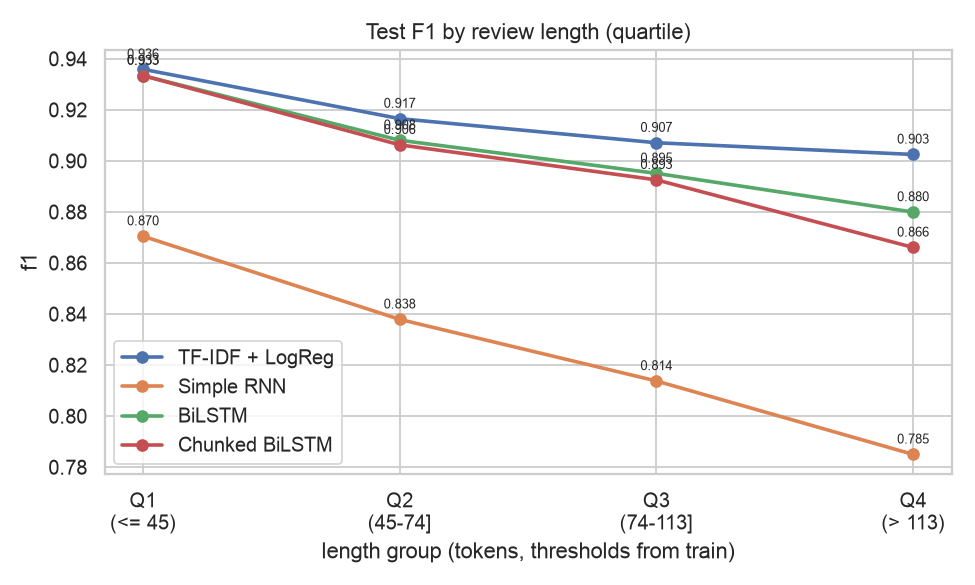

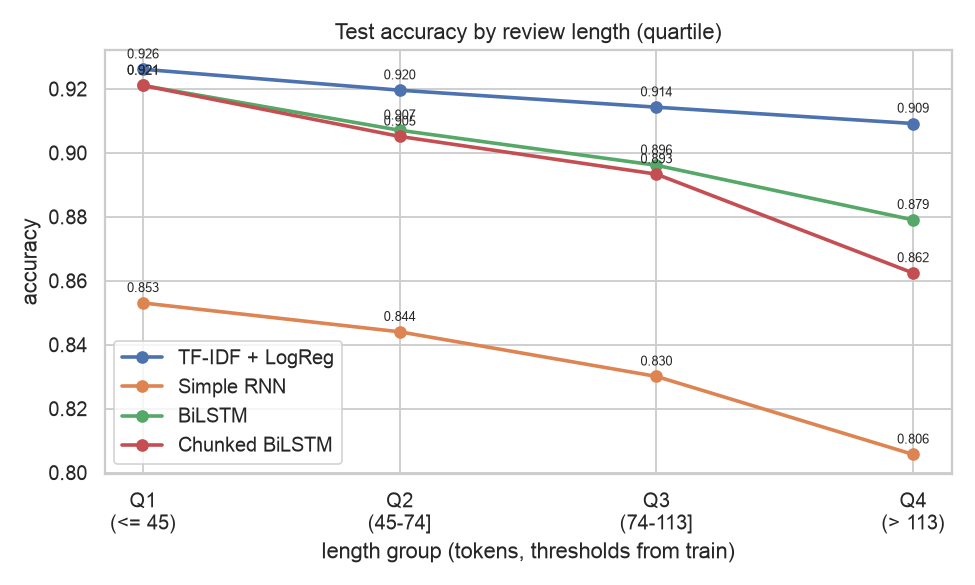

In [16]:
display(Image(C.FIG_DIR / "f1_by_quartile.png"))
display(Image(C.FIG_DIR / "accuracy_by_quartile.png"))

### Short-vs-long gap and the effect of truncation

In [17]:
display(pd.read_csv(C.TABLE_DIR / "short_long_gap.csv").round(4))
pd.read_csv(C.TABLE_DIR / "truncation_effect.csv").round(4)

,model,acc_short,acc_long,f1_short,f1_long,acc_gap_short_minus_long,f1_gap_short_minus_long
0,tfidf_lr,0.9229,0.9117,0.9272,0.9048,0.0112,0.0224
1,rnn,0.8486,0.8177,0.8557,0.7993,0.0309,0.0565
2,lstm,0.9142,0.8875,0.9219,0.8874,0.0267,0.0346
3,chunked_lstm,0.9132,0.8777,0.9211,0.8789,0.0355,0.0422


,model,subset,n,accuracy,precision,recall,f1
0,tfidf_lr,"long, fits in max_len",8612,0.9124,0.9140,0.8977,0.9058
1,tfidf_lr,truncated (> max_len),879,0.9044,0.8965,0.8920,0.8942
2,rnn,"long, fits in max_len",8612,0.8219,0.8271,0.7841,0.8050
3,rnn,truncated (> max_len),879,0.7770,0.7869,0.6960,0.7387
4,lstm,"long, fits in max_len",8612,0.8914,0.8399,0.9495,0.8913
5,lstm,truncated (> max_len),879,0.8487,0.7766,0.9347,0.8483
6,chunked_lstm,"long, fits in max_len",8612,0.8821,0.8253,0.9497,0.8832
7,chunked_lstm,truncated (> max_len),879,0.8339,0.7500,0.9497,0.8381


In [18]:
comp = pd.read_csv(C.TABLE_DIR / "chunked_variants_comparison.csv")
comp.pivot_table(index=["grouping", "group"], columns="model_name", values="accuracy").round(4)

model_name      BiLSTM  Chunked BiLSTM  Hybrid BiLSTM (chunk only if > max_len)
grouping group                                                                 
overall  all    0.9015          0.8964                                   0.9008
quartile Q1     0.9211          0.9211                                   0.9211
         Q2     0.9071          0.9051                                   0.9071
         Q3     0.8961          0.8934                                   0.8961
         Q4     0.8791          0.8624                                   0.8764
two_way  long   0.8875          0.8777                                   0.8861
         short  0.9142          0.9132                                   0.9142

## 5. Calibration and human-review flagging (feature D)
Confidence = max(p, 1−p). The flagging threshold is chosen on the **validation** set as the smallest threshold whose auto-accepted predictions reach 95 % accuracy; it is then applied unchanged to the test set.


Calibration (test):
        model      model_name    ECE  Brier
    tfidf_lr TF-IDF + LogReg 0.0057 0.0614
         rnn      Simple RNN 0.0317 0.1277
        lstm          BiLSTM 0.0671 0.0786
chunked_lstm  Chunked BiLSTM 0.0632 0.0824

Human-review flagging (threshold chosen on val):
        model      model_name  threshold_from_val  target_val_accuracy  target_reached_on_val  test_pct_flagged  test_acc_all  test_acc_unflagged  test_acc_flagged  acc_gain_pts  pct_flagged_short  pct_flagged_long
    tfidf_lr TF-IDF + LogReg              0.6950                 0.95                   True              9.42        0.9176              0.9497            0.6088        3.2113             8.9733            9.9147
         rnn      Simple RNN              0.8992                 0.95                  False             49.95        0.8340              0.9125            0.7553        7.8538            48.4537           51.6068
        lstm          BiLSTM              0.9350                 0.95 

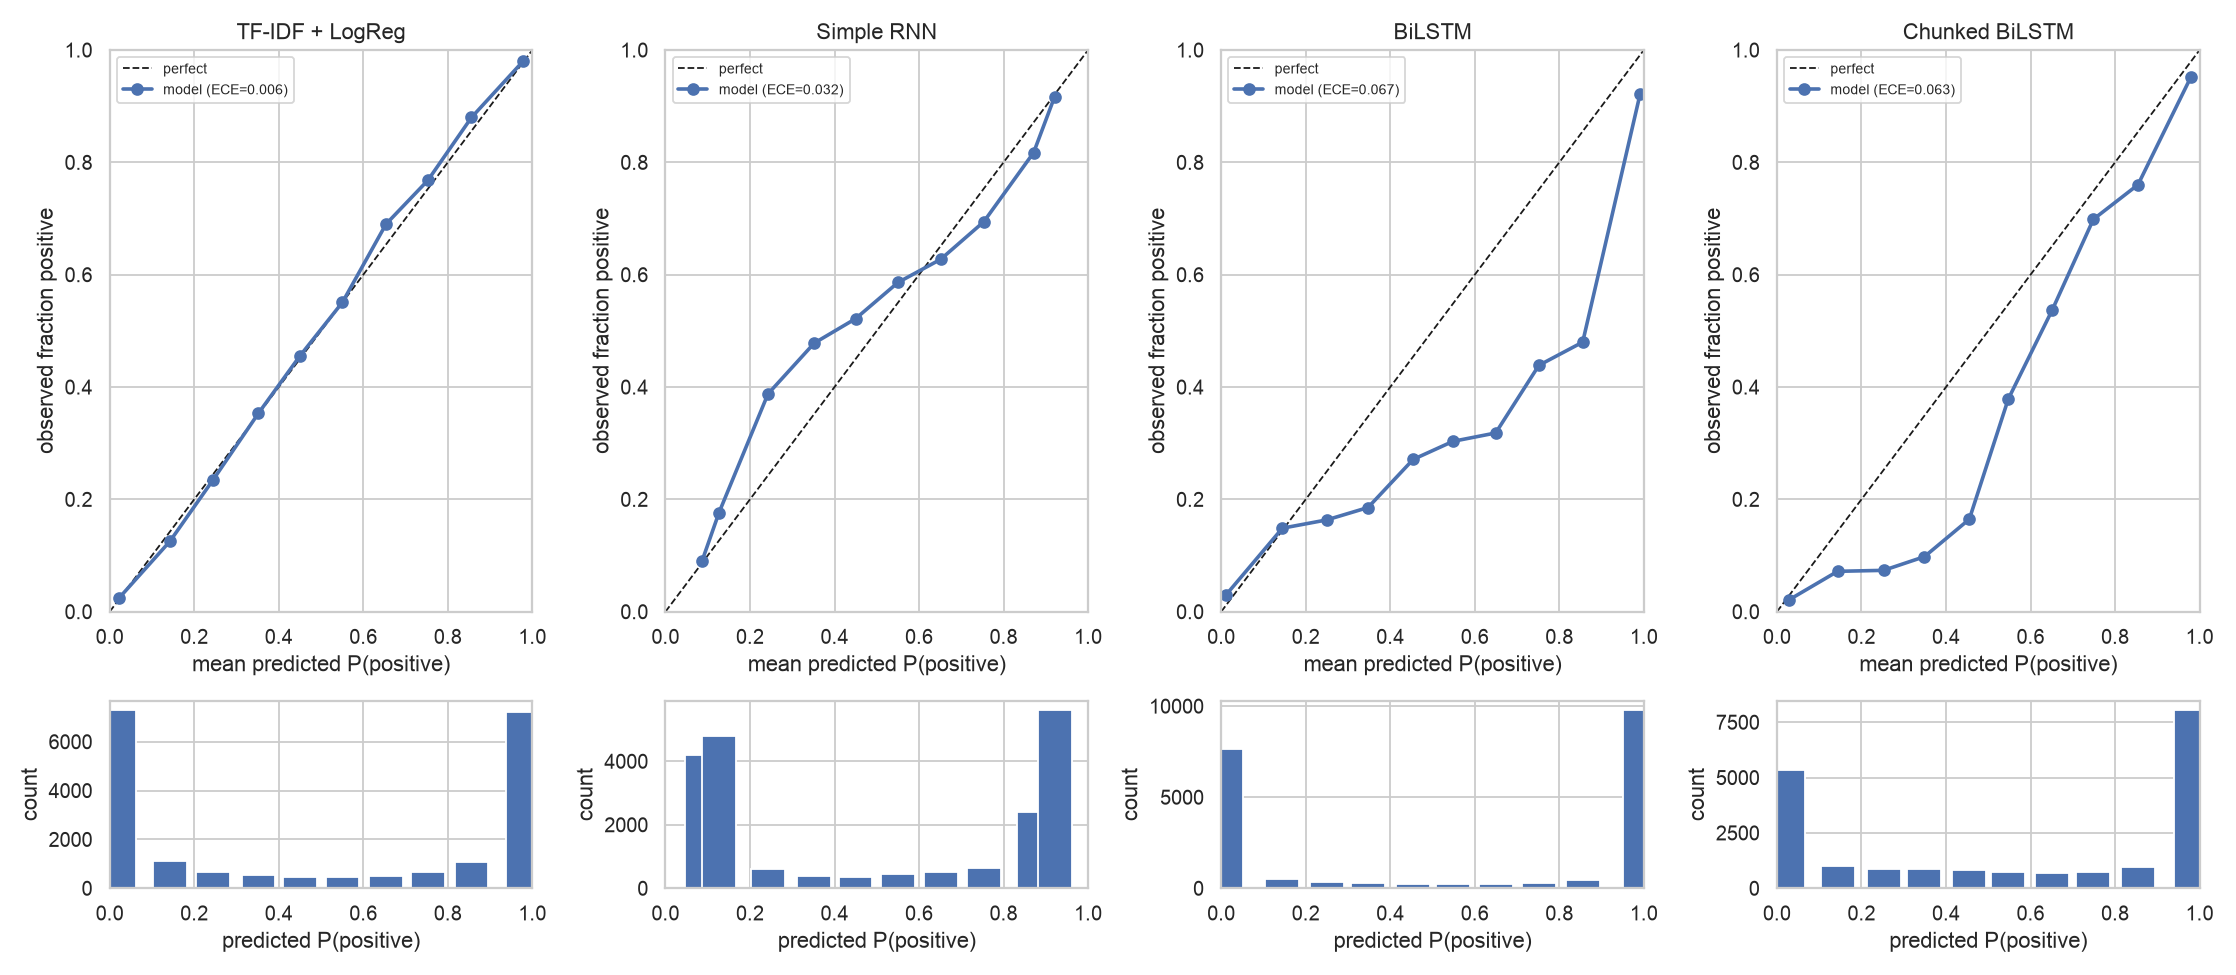

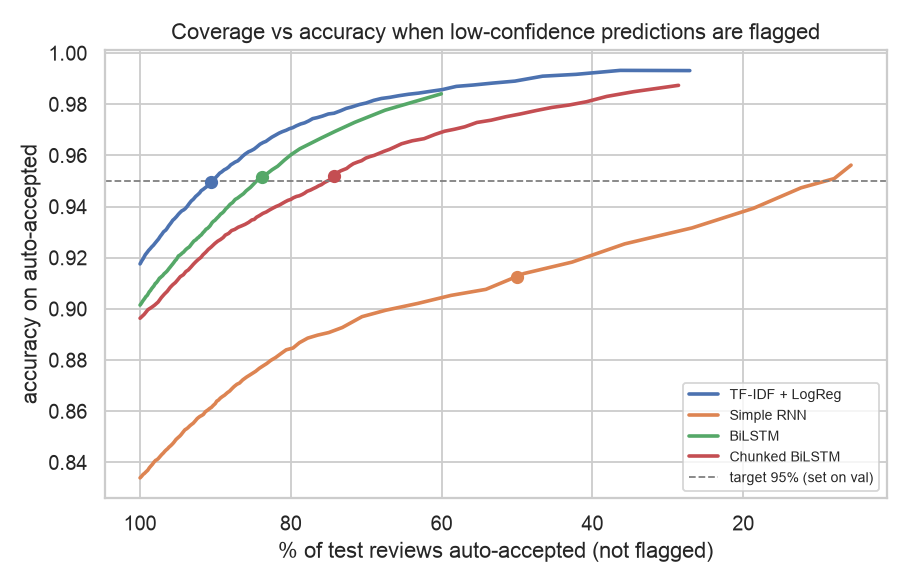

In [19]:
from src import calibration
calibration.main()
display(Image(C.FIG_DIR / "reliability_diagrams.png"))
display(Image(C.FIG_DIR / "coverage_vs_accuracy.png"))

## 6. Error analysis
20 misclassified test reviews per model (5 per length quartile, seeded). The *likely cause* is a transparent heuristic tag (truncation / negation / mixed sentiment / sarcasm / other), not a human label.

In [20]:
from src import error_analysis
err = error_analysis.main()
err.groupby("model").head(4)[["model_name", "true_label", "prob_positive", "length_quartile", "likely_cause", "review"]]


Cause tags among the 20 sampled errors per model:
        model  truncation  negation  mixed sentiment  sarcasm  other
    tfidf_lr           0         5               15        4      4
         rnn           1         2               11        2      7
        lstm           2         3               15        4      4
chunked_lstm           0         2               13        2      5


,model_name,true_label,prob_positive,length_quartile,likely_cause,review
0,TF-IDF + LogReg,0,0.5099,Q1,negation ('not ... like'),"Up Jumped The Devil. This wasn't something I would enjoy, my husband ordered it for me so he will read it. The story..."
1,TF-IDF + LogReg,0,0.5934,Q1,"other: ambiguous wording, domain-specific vocabulary or possible label noise",dimensions. Why isn't there a list that shows the dimensions of the clock radio/phone. It has to fit on a nightstand...
2,TF-IDF + LogReg,1,0.3750,Q1,"other: ambiguous wording, domain-specific vocabulary or possible label noise","Try the ones from B&H. If you want these at a better price, try B&H in New York. They sell them for $10.00 and free ..."
3,TF-IDF + LogReg,1,0.1910,Q1,"mixed sentiment (1 pos / 0 neg cue words, contrast marker 'but')",I wish the rubber parts were softer. I wish the rubber used for it was softer. The curler itself seems to be nicely ...
20,Simple RNN,0,0.8713,Q1,"other: ambiguous wording, domain-specific vocabulary or possible label noise",when they say gradual... ...they mean it. could barely notice any color change after two applications. so if subtle ...
21,Simple RNN,1,0.3598,Q1,"other: ambiguous wording, domain-specific vocabulary or possible label noise",I found Skeafe. I found Skeafe in County Cork in the 17th Century! Plus this book is hardbound which really helps be...
22,Simple RNN,0,0.8104,Q1,negation ('not ... best'); possible sarcasm / irony,"this album is by far not her best. about the only good song on hear is ""the lucky one"" , not worth the money , some ..."
23,Simple RNN,1,0.4508,Q1,"other: ambiguous wording, domain-specific vocabulary or possible label noise",lancets. I sometimes have to buy extra that my insurance won't cover. These are priced competitively and are of qual...
40,BiLSTM,0,0.7363,Q1,possible sarcasm / irony,Interchangeable Superhero Tunes!? I liked this song back when it was called 'Kiss from a Rose' by Seal. Sheesh!!
41,BiLSTM,0,0.9550,Q1,mixed sentiment (1 pos / 1 neg cue words),air bed review. It came defective. The first inflation reveiled a good size hole in the top that obviously leaked lo...


## 7. Summary (computed from the result tables)

In [21]:
ov = pd.read_csv(C.TABLE_DIR / "metrics_overall.csv")
gap = pd.read_csv(C.TABLE_DIR / "short_long_gap.csv")
fl = pd.read_csv(C.TABLE_DIR / "human_review_flagging.csv")
best = ov.loc[ov.f1.idxmax()]
print(f"Best overall model: {best.model_name}  (accuracy {best.accuracy:.4f}, F1 {best.f1:.4f})")
for _, r in gap.iterrows():
    print(f"{C.MODEL_NAMES[r.model]:<16} acc short {r.acc_short:.4f} | long {r.acc_long:.4f} | "
          f"gap {r.acc_gap_short_minus_long*100:+.2f} pts")
for _, r in fl.iterrows():
    print(f"{r.model_name:<16} flags {r.test_pct_flagged:.1f}% of test -> accuracy on the rest "
          f"{r.test_acc_unflagged:.4f} (vs {r.test_acc_all:.4f})")

Best overall model: TF-IDF + LogReg  (accuracy 0.9176, F1 0.9173)
TF-IDF + LogReg  acc short 0.9229 | long 0.9117 | gap +1.12 pts
Simple RNN       acc short 0.8486 | long 0.8177 | gap +3.09 pts
BiLSTM           acc short 0.9142 | long 0.8875 | gap +2.67 pts
Chunked BiLSTM   acc short 0.9132 | long 0.8777 | gap +3.55 pts
TF-IDF + LogReg  flags 9.4% of test -> accuracy on the rest 0.9497 (vs 0.9176)
Simple RNN       flags 50.0% of test -> accuracy on the rest 0.9125 (vs 0.8339)
BiLSTM           flags 16.2% of test -> accuracy on the rest 0.9516 (vs 0.9015)
Chunked BiLSTM   flags 25.7% of test -> accuracy on the rest 0.9518 (vs 0.8963)
